# Scorecard de crédito: de una regresión ingenua a un modelo estable en el tiempo

**Perfil:** riesgo de crédito (productos). **Datos:** sintéticos con semilla fija, generados con una función conocida para poder comprobar si el modelo recupera lo que sabemos que es verdad.

## Qué se hace aquí

El notebook sigue el camino real de desarrollo de un scorecard, incluidos los tropiezos:

1. Se genera una población con problemas realistas: relaciones no lineales, valores faltantes **informativos**, y una deriva de la población en el tiempo.
2. **Versión 1 (ingenua):** regresión logística sobre las variables crudas, con validación aleatoria.
3. **Diagnóstico:** se mira dónde falla (no linealidad, faltantes, estabilidad temporal).
4. **Versión 2:** discretización por cuantiles con Weight of Evidence.
5. **Versión 3:** discretización con monotonía forzada y manejo explícito de faltantes.
6. **Una hipótesis que se comprueba en lugar de suponerse:** la población deriva fuera del rango visto. Se mide cuánto error viene de ahí, se intenta corregir (v4), se prueba recalibrar y reentrenar, y se define un monitor.
7. Escalamiento a puntos de scorecard, análisis de punto de corte, robustez y **pruebas automáticas**.

## Índice

1. Configuración · 2. Datos · 3. Exploración · 4. Versión 1 · 5. Diagnóstico · 6. Versión 2 (WoE) · 7. Versión 3 (monotonía) · 8. Modelo final y diagnóstico del nivel de PD · 9. Scorecard · 10. Estabilidad (PSI) · 11. Punto de corte · 12. Robustez · 13. Pruebas · 14. Conclusiones y límites

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.2 | pandas 2.2.3


## 2. Datos sintéticos con una verdad conocida

Se genera una cartera de 40.000 créditos originados durante 36 meses. Lo que se sabe del proceso generador:

- La **utilización** tiene un efecto *convexo* (crece más rápido cuando es alta) y además **deriva al alza** con el tiempo.
- La **edad** tiene forma de U: los muy jóvenes y los muy mayores incumplen más.
- El **ingreso** falta en cerca del 4–10 % de los casos y la ausencia es **informativa**: quien incumple omite el ingreso con más frecuencia.
- La **antigüedad laboral** y la **mora previa** tienen efectos monótonos.

Como el proceso es conocido, al final se puede comprobar si el modelo capturó lo correcto.

In [2]:
def generar(n=40_000, meses=36, seed=SEED):
    rng = np.random.default_rng(seed)
    mes = rng.integers(0, meses, n)
    ingreso = rng.lognormal(8.0, 0.5, n)
    edad = rng.integers(21, 70, n)
    util = np.clip(rng.beta(2, 3, n) + 0.008 * mes, 0, 1.2)
    mora = rng.poisson(0.4, n)
    antig = np.minimum(rng.exponential(4, n), 30)
    z = (-3.6 - 0.00018 * (ingreso - 3000) + 2.6 * util ** 2
         + 0.0011 * (edad - 45) ** 2 + 0.55 * np.minimum(mora, 4) - 0.08 * np.minimum(antig, 10))
    p = 1 / (1 + np.exp(-z))
    y = (rng.random(n) < p).astype(int)
    falta = rng.random(n) < (0.03 + 0.07 * y)
    ingreso_obs = np.where(falta, np.nan, ingreso)
    df = pd.DataFrame({"mes": mes, "ingreso": ingreso_obs, "edad": edad, "utilizacion": util,
                       "mora_previa": mora, "antiguedad": antig, "default": y})
    return df, p


df, p_verdadera = generar()
print(df.shape)
df.head()

(40000, 7)


,mes,ingreso,edad,utilizacion,mora_previa,antiguedad,default
0,30,"1,635.3558",43,0.7149,1,7.6472,0
1,6,"1,320.0978",51,0.4100,0,5.1316,0
2,0,"3,947.4165",43,0.5370,1,1.8532,0
3,23,"4,730.2678",53,0.4054,1,3.9287,0
4,13,"8,328.9265",25,0.4607,0,5.7434,0


## 3. Exploración inicial

In [3]:
resumen = df.describe(percentiles=[.01, .5, .99]).T
resumen["faltantes_%"] = df.isna().mean() * 100
resumen

,count,mean,std,min,1%,50%,99%,max,faltantes_%
mes,"40,000.0000",17.5250,10.3825,0.0000,0.0000,18.0000,35.0000,35.0000,0.0000
ingreso,"38,495.0000","3,375.6007","1,787.6533",394.5221,932.8306,"2,980.7119","9,506.7047","22,174.9755",3.7625
edad,"40,000.0000",44.9483,14.1309,21.0000,21.0000,45.0000,69.0000,69.0000,0.0000
utilizacion,"40,000.0000",0.5411,0.2171,0.0128,0.1132,0.5298,1.0474,1.2000,0.0000
mora_previa,"40,000.0000",0.4029,0.6358,0.0000,0.0000,0.0000,2.0000,5.0000,0.0000
antiguedad,"40,000.0000",4.0070,3.9951,0.0002,0.0351,2.7889,18.4557,30.0000,0.0000
default,"40,000.0000",0.0883,0.2838,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000


In [4]:
print(f"Tasa de incumplimiento global: {df['default'].mean():.3%}")
print(f"Probabilidad verdadera media (conocida solo por ser sintético): {p_verdadera.mean():.3%}")
print()
print("Tasa de faltantes en ingreso según el resultado:")
print(df.groupby("default")["ingreso"].apply(lambda s: s.isna().mean()).rename("faltante").to_frame())

Tasa de incumplimiento global: 8.832%
Probabilidad verdadera media (conocida solo por ser sintético): 8.902%

Tasa de faltantes en ingreso según el resultado:
         faltante
default          
0          0.0311
1          0.1047


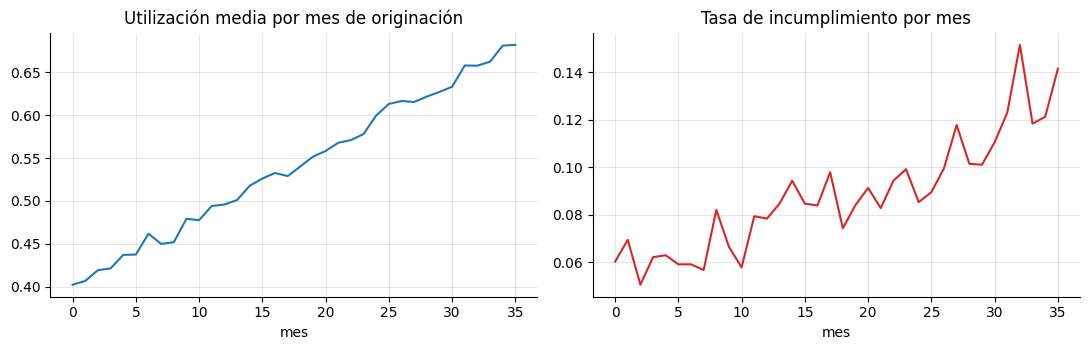

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
por_mes = df.groupby("mes").agg(util=("utilizacion", "mean"), tasa=("default", "mean"))
ax[0].plot(por_mes.index, por_mes["util"]); ax[0].set_title("Utilización media por mes de originación")
ax[1].plot(por_mes.index, por_mes["tasa"], color="C3"); ax[1].set_title("Tasa de incumplimiento por mes")
for a in ax: a.set_xlabel("mes")
plt.tight_layout(); plt.show()

**Lectura:** la utilización sube con el tiempo y el incumplimiento sube con ella. Esto importa: una validación aleatoria mezcla pasado y futuro y **no detecta** que la población cambió. Por eso se separa una muestra *fuera de tiempo* (OOT).

### Partición: desarrollo, validación y fuera de tiempo

In [6]:
OOT_DESDE = 30
desarrollo = df[df["mes"] < OOT_DESDE].copy()
oot = df[df["mes"] >= OOT_DESDE].copy()
train, valid = train_test_split(desarrollo, test_size=0.3, random_state=SEED, stratify=desarrollo["default"])
print({"train": len(train), "valid": len(valid), "oot": len(oot)})
print("Tasa default:", {k: round(v["default"].mean(), 4) for k, v in {"train": train, "valid": valid, "oot": oot}.items()})
VARS = ["ingreso", "edad", "utilizacion", "mora_previa", "antiguedad"]

{'train': 23324, 'valid': 9996, 'oot': 6680}
Tasa default: {'train': np.float64(0.0804), 'valid': np.float64(0.0804), 'oot': np.float64(0.1277)}


### Métricas que se usarán

- **AUC / Gini** (`Gini = 2·AUC − 1`): poder de ordenamiento.
- **KS:** máxima separación entre las distribuciones acumuladas de buenos y malos.
- **Brier:** calidad de la probabilidad (calibración y discriminación a la vez).

In [7]:
def ks_stat(y, p):
    orden = np.argsort(p)
    y = np.asarray(y)[orden]
    malos = np.cumsum(y) / y.sum()
    buenos = np.cumsum(1 - y) / (1 - y).sum()
    return float(np.max(np.abs(malos - buenos)))


def evaluar(y, p):
    auc = roc_auc_score(y, p)
    brier = brier_score_loss(y, p)
    base = np.mean(y) * (1 - np.mean(y))                 # Brier de predecir siempre la tasa base
    return {"AUC": auc, "Gini": 2 * auc - 1, "KS": ks_stat(y, p), "Brier": brier, "BSS": 1 - brier / base}


def tabla_metricas(modelo_pred, nombre):
    filas = {k: evaluar(d["default"], modelo_pred(d)) for k, d in
             (("train", train), ("valid", valid), ("oot", oot))}
    out = pd.DataFrame(filas).T
    out.insert(0, "modelo", nombre)
    return out

# comprobacion de las metricas con casos triviales (primera prueba, antes de usarlas)
y_prueba = np.array([0, 0, 1, 1])
assert abs(evaluar(y_prueba, np.array([.1, .2, .8, .9]))["AUC"] - 1.0) < 1e-12
assert abs(evaluar(y_prueba, np.array([.9, .8, .2, .1]))["AUC"] - 0.0) < 1e-12
assert abs(ks_stat(y_prueba, np.array([.1, .2, .8, .9])) - 1.0) < 1e-12
print("metricas verificadas con casos triviales")

metricas verificadas con casos triviales


## 4. Versión 1: regresión logística sobre variables crudas

La primera aproximación es la que haría cualquiera con prisa: imputar el ingreso con la mediana y ajustar una logística sobre las variables tal cual.

In [8]:
mediana_ingreso = train["ingreso"].median()


def X_v1(d):
    X = d[VARS].copy()
    X["ingreso"] = X["ingreso"].fillna(mediana_ingreso)
    return X


m1 = LogisticRegression(max_iter=2000).fit((lambda X: (X - X.mean()) / X.std())(X_v1(train)), train["default"])
mu1, sd1 = X_v1(train).mean(), X_v1(train).std()
pred_v1 = lambda d: m1.predict_proba((X_v1(d) - mu1) / sd1)[:, 1]
met_v1 = tabla_metricas(pred_v1, "v1 logistica cruda")
met_v1

,modelo,AUC,Gini,KS,Brier,BSS
train,v1 logistica cruda,0.7279,0.4559,0.3435,0.0687,0.0706
valid,v1 logistica cruda,0.7330,0.4660,0.3573,0.0684,0.0747
oot,v1 logistica cruda,0.7421,0.4842,0.3684,0.0999,0.1027


El resultado parece aceptable, pero hay que desconfiar de un número solo. Dos observaciones ya aparecen:

- La métrica en **OOT** es distinta de la de validación.
- El Brier sube en OOT (0,068 → 0,100), pero **no es comparable entre muestras con distinta tasa base**: el Brier de no saber nada ya sube con la tasa de incumplimiento. Por eso se agrega el *Brier skill score* (BSS = 1 − Brier / Brier de predecir siempre la tasa base), que sí es comparable.

Miremos la calibración antes de seguir.

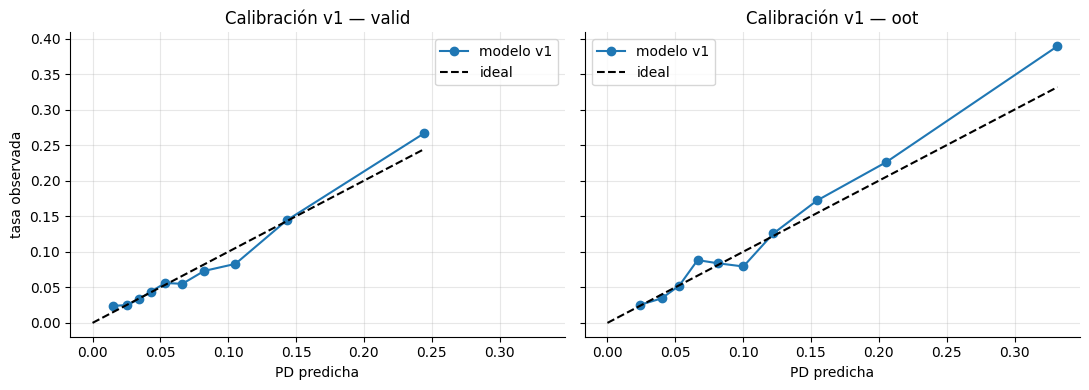

In [9]:
def calibracion(y, p, bins=10):
    t = pd.DataFrame({"y": y, "p": p})
    t["g"] = pd.qcut(t["p"], bins, duplicates="drop")
    return t.groupby("g", observed=True).agg(p_media=("p", "mean"), tasa=("y", "mean"), n=("y", "size"))


fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for a, (nombre, d) in zip(ax, (("valid", valid), ("oot", oot))):
    c = calibracion(d["default"], pred_v1(d))
    a.plot(c["p_media"], c["tasa"], "o-", label="modelo v1"); a.plot([0, c["p_media"].max()], [0, c["p_media"].max()], "k--", label="ideal")
    a.set_title(f"Calibración v1 — {nombre}"); a.set_xlabel("PD predicha"); a.legend()
ax[0].set_ylabel("tasa observada"); plt.tight_layout(); plt.show()

In [10]:
print(f"PD media predicha en OOT: {pred_v1(oot).mean():.4f}  |  tasa observada en OOT: {oot['default'].mean():.4f}")

PD media predicha en OOT: 0.1179  |  tasa observada en OOT: 0.1277


**Hallazgo 1:** en OOT el modelo predice una PD media de 11,8 % frente a 12,8 % observado: **subestima cerca de 1 punto porcentual** (≈ 8 % en términos relativos). Una validación aleatoria no podía mostrarlo. Todavía no se sabe *por qué*: en la sección 8 se comprueba una hipótesis concreta en lugar de suponerla.

## 5. Diagnóstico: ¿qué no está capturando la versión 1?

Se grafica la tasa de incumplimiento por tramos de cada variable. Si la relación fuera lineal en el logit, las curvas serían suaves y monótonas. Se separa también el grupo de ingreso faltante.

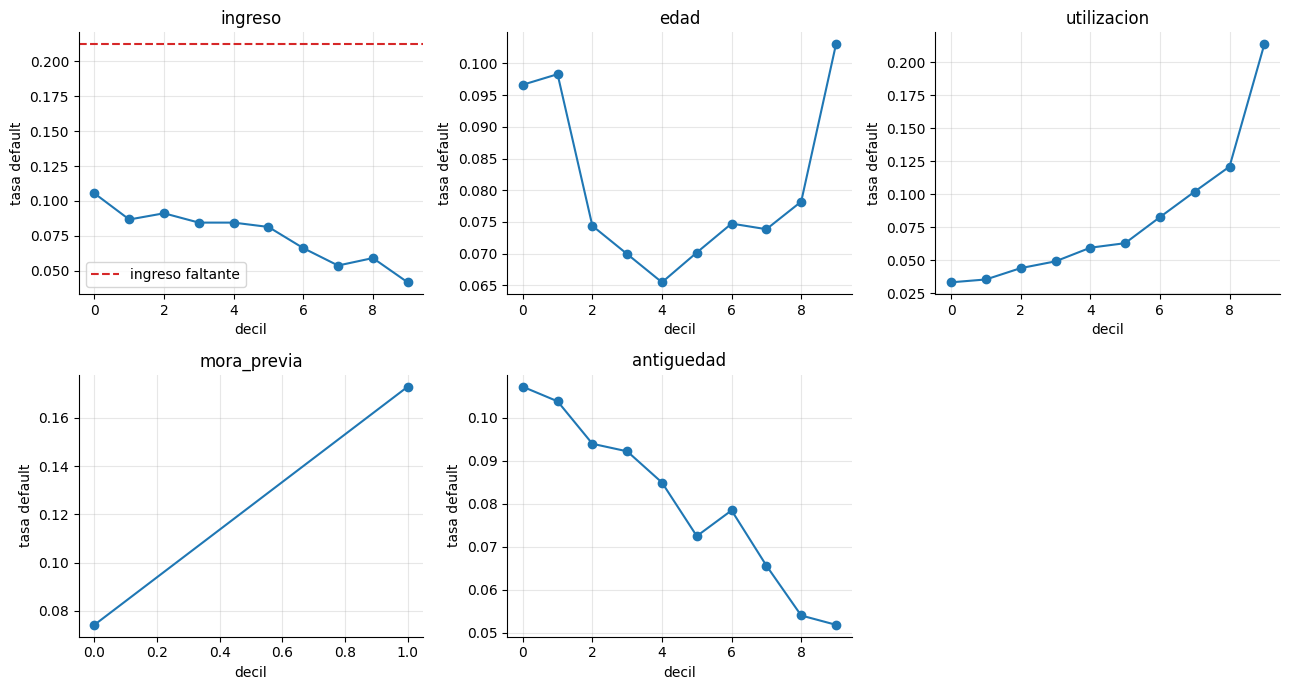

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, v in zip(axes.ravel(), VARS):
    x = train[v]
    g = pd.qcut(x, 10, duplicates="drop")
    t = train.groupby(g, observed=True)["default"].agg(["mean", "size"])
    ax.plot(range(len(t)), t["mean"], "o-")
    ax.set_title(v); ax.set_xlabel("decil"); ax.set_ylabel("tasa default")
    if v == "ingreso":
        ax.axhline(train.loc[train["ingreso"].isna(), "default"].mean(), color="C3", ls="--", label="ingreso faltante")
        ax.legend()
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

In [12]:
print("Tasa default con ingreso faltante:", round(train.loc[train["ingreso"].isna(), "default"].mean(), 4))
print("Tasa default con ingreso presente:", round(train.loc[train["ingreso"].notna(), "default"].mean(), 4))

Tasa default con ingreso faltante: 0.2121
Tasa default con ingreso presente: 0.0755


**Hallazgos del diagnóstico**

1. `utilizacion` es **convexa** (creciente y cada vez más empinada) y `edad` tiene forma de **U**: una logística lineal sobre la variable cruda las promedia y pierde señal.
2. El ingreso faltante tiene una tasa de incumplimiento **claramente mayor**. Imputarlo con la mediana **destruye** esa señal.
3. `mora_previa` y `antiguedad` son monótonas, así que el modelo lineal las maneja bien.

**Plan:** discretizar cada variable en tramos y reemplazar cada tramo por su Weight of Evidence. Eso captura formas no lineales y permite que `faltante` sea un tramo propio.

## 6. Versión 2: discretización por cuantiles y WoE

Para cada tramo *i*:

$$\mathrm{WoE}_i=\ln\frac{\%\text{buenos}_i}{\%\text{malos}_i},\qquad \mathrm{IV}=\sum_i(\%\text{buenos}_i-\%\text{malos}_i)\,\mathrm{WoE}_i$$

Regla práctica de IV: <0,02 sin poder; 0,02–0,1 débil; 0,1–0,3 medio; 0,3–0,5 fuerte; >0,5 sospechoso.

Se implementa una clase `WoEBinner` que **solo aprende de entrenamiento**. Primero sin monotonía (versión 2) y luego con ella (versión 3).

In [13]:
class WoEBinner:
    def __init__(self, n_bins=10, min_frac=0.03, monotono=False):
        self.n_bins, self.min_frac, self.monotono = n_bins, min_frac, monotono

    def fit(self, x, y):
        x = np.asarray(x, float); y = np.asarray(y, int)
        na = np.isnan(x)
        xv, yv = x[~na], y[~na]
        u = np.unique(xv)
        if len(u) <= self.n_bins:                       # variable discreta: un tramo por valor
            cortes = list((u[:-1] + u[1:]) / 2)
        else:
            q = np.unique(np.quantile(xv, np.linspace(0, 1, self.n_bins + 1)))
            cortes = list(q[1:-1])
        idx = np.digitize(xv, cortes)
        k = len(cortes) + 1
        malos = np.bincount(idx, weights=yv, minlength=k).astype(float)
        tot = np.bincount(idx, minlength=k).astype(float)
        grupos = [{"m": malos[i], "t": tot[i], "hi": cortes[i] if i < len(cortes) else np.inf} for i in range(k)]
        n_val = len(xv)
        signo = 1 if spearmanr(xv, yv)[0] >= 0 else -1

        def tasa(g): return g["m"] / g["t"]

        def fusionar(i):
            a, b = grupos[i], grupos[i + 1]
            grupos[i:i + 2] = [{"m": a["m"] + b["m"], "t": a["t"] + b["t"], "hi": b["hi"]}]

        cambio = True
        while cambio and len(grupos) > 1:
            cambio = False
            for i, g in enumerate(grupos):                       # tramos muy pequenos
                if g["t"] / n_val < self.min_frac and len(grupos) > 1:
                    vecinos = [j for j in (i - 1, i + 1) if 0 <= j < len(grupos)]
                    j = min(vecinos, key=lambda j: abs(tasa(grupos[j]) - tasa(g)))
                    fusionar(min(i, j)); cambio = True; break
            if cambio: continue
            if self.monotono:                                    # violaciones de monotonia
                for i in range(len(grupos) - 1):
                    if signo * (tasa(grupos[i + 1]) - tasa(grupos[i])) < 0:
                        fusionar(i); cambio = True; break

        self.cortes_ = [g["hi"] for g in grupos[:-1]]
        self.signo_ = signo
        idx = np.digitize(xv, self.cortes_)
        k = len(self.cortes_) + 1
        B = y.sum(); G = len(y) - B
        m = np.bincount(idx, weights=yv, minlength=k) + 0.5
        t = np.bincount(idx, minlength=k) + 1.0
        g_ = t - m
        self.woe_ = np.log((g_ / (G + 0.5 * k)) / (m / (B + 0.5 * k)))
        self.n_ = t - 1.0
        self.tasa_ = (m - 0.5) / np.maximum(t - 1.0, 1)
        self.hay_na_ = bool(na.any())
        if self.hay_na_:
            mn, tn = y[na].sum() + 0.5, na.sum() + 1.0
            self.woe_na_ = float(np.log(((tn - mn) / (G + 0.5)) / (mn / (B + 0.5))))
            self.n_na_, self.tasa_na_ = int(na.sum()), float(y[na].mean())
        else:
            self.woe_na_, self.n_na_, self.tasa_na_ = 0.0, 0, np.nan
        dist_b = m / (B + 0.5 * k); dist_g = g_ / (G + 0.5 * k)
        self.iv_ = float(((dist_g - dist_b) * self.woe_).sum())
        if self.hay_na_:
            db, dg = mn / (B + 0.5), (tn - mn) / (G + 0.5)
            self.iv_ += float((dg - db) * self.woe_na_)
        return self

    def transform(self, x):
        x = np.asarray(x, float)
        na = np.isnan(x)
        out = self.woe_[np.digitize(np.where(na, 0.0, x), self.cortes_)]
        return np.where(na, self.woe_na_, out)

    def tabla(self):
        lim = [-np.inf] + list(self.cortes_) + [np.inf]
        t = pd.DataFrame({"desde": lim[:-1], "hasta": lim[1:], "n": self.n_, "tasa_default": self.tasa_, "WoE": self.woe_})
        if self.hay_na_:
            t.loc[len(t)] = [np.nan, np.nan, self.n_na_, self.tasa_na_, self.woe_na_]
            t.index = list(range(len(t) - 1)) + ["faltante"]
        return t

In [14]:
def ajustar_binners(datos, **kw):
    return {v: WoEBinner(**kw).fit(datos[v], datos["default"]) for v in VARS}


def matriz_woe(binners, d):
    return pd.DataFrame({v: binners[v].transform(d[v]) for v in VARS}, index=d.index)


def iv_tabla(binners):
    return pd.Series({v: b.iv_ for v, b in binners.items()}, name="IV").sort_values(ascending=False).to_frame()


bin_v2 = ajustar_binners(train, n_bins=10, monotono=False)
iv_tabla(bin_v2)

,IV
utilizacion,0.4140
ingreso,0.1481
mora_previa,0.1361
antiguedad,0.0648
edad,0.0332


In [15]:
m2 = LogisticRegression(C=1.0, max_iter=2000).fit(matriz_woe(bin_v2, train), train["default"])
pred_v2 = lambda d: m2.predict_proba(matriz_woe(bin_v2, d))[:, 1]
met_v2 = tabla_metricas(pred_v2, "v2 WoE cuantiles")
pd.concat([met_v1, met_v2])

,modelo,AUC,Gini,KS,Brier,BSS
train,v1 logistica cruda,0.7279,0.4559,0.3435,0.0687,0.0706
valid,v1 logistica cruda,0.7330,0.4660,0.3573,0.0684,0.0747
oot,v1 logistica cruda,0.7421,0.4842,0.3684,0.0999,0.1027
train,v2 WoE cuantiles,0.7420,0.4839,0.3568,0.0682,0.0777
valid,v2 WoE cuantiles,0.7554,0.5108,0.3895,0.0671,0.0923
oot,v2 WoE cuantiles,0.7466,0.4933,0.3705,0.0996,0.1057


La mejora en validación es clara (Gini 0,466 → 0,511); en OOT es bastante menor (0,484 → 0,493). Pero hay un detalle que un analista cuidadoso revisaría: **¿los WoE son monótonos?** En una variable como `antiguedad` o `mora_previa`, una violación de monotonía suele ser ruido, no señal, y complica explicar el modelo a un comité o a un regulador.

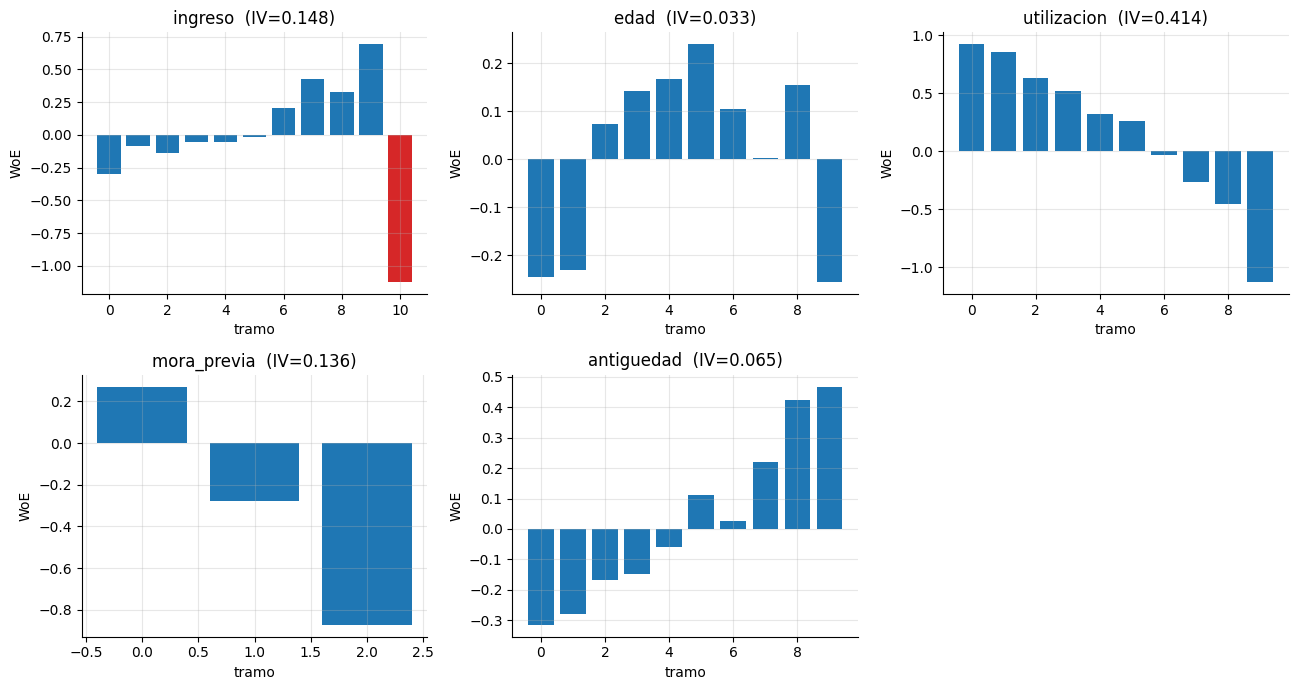

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, v in zip(axes.ravel(), VARS):
    t = bin_v2[v].tabla()
    ax.bar(range(len(t)), t["WoE"], color=["C3" if i == "faltante" else "C0" for i in t.index])
    ax.set_title(f"{v}  (IV={bin_v2[v].iv_:.3f})"); ax.set_xlabel("tramo"); ax.set_ylabel("WoE")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

In [17]:
def es_monotono(binner):
    w = binner.woe_
    d = np.diff(w)
    return bool(np.all(d <= 1e-12) or np.all(d >= -1e-12))

print({v: es_monotono(b) for v, b in bin_v2.items()})

{'ingreso': False, 'edad': False, 'utilizacion': True, 'mora_previa': True, 'antiguedad': False}


Lo que muestra la comprobación: `edad` no es monótona, y **debe** no serlo (la verdad tiene forma de U). `utilizacion` y `mora_previa` ya salieron monótonas. Pero `ingreso` y `antiguedad` tienen quiebres, y para ellas la relación verdadera es monótona decreciente, así que esos quiebres son **ruido de muestra**.

Una corrección sobre el planteamiento inicial de este análisis: se pensó tratar `utilizacion` como no monótona por ser convexa, pero **convexa no es no monótona**: es creciente y acelerada. Se fuerza monotonía en `ingreso`, `utilizacion`, `mora_previa` y `antiguedad`, y solo `edad` queda libre. Es una decisión de modelación basada en conocimiento del negocio, no un automatismo; por eso se parametriza por variable.

## 7. Versión 3: monotonía donde la teoría la exige

Se fusionan tramos adyacentes que violan la dirección esperada (algoritmo de *pool adjacent violators* sobre la tasa de incumplimiento) y se exige un tamaño mínimo por tramo.

Un ajuste surgido al revisar las tablas: la primera versión del binner por cuantiles dejaba `mora_previa` (valores enteros 0, 1, 2, …) con solo **2 tramos**, porque los cuantiles coinciden. Ahora, si una variable tiene pocos valores distintos, cada valor es un tramo inicial; así `mora_previa` queda con 3 tramos (0, 1 y 2 o más) y su IV sube de 0,111 a 0,136.

In [18]:
MONOTONAS = {"ingreso": True, "edad": False, "utilizacion": True, "mora_previa": True, "antiguedad": True}


def ajustar_binners_v3(datos, n_bins=10, min_frac=0.03):
    return {v: WoEBinner(n_bins=n_bins, min_frac=min_frac, monotono=MONOTONAS[v]).fit(datos[v], datos["default"]) for v in VARS}


bin_v3 = ajustar_binners_v3(train)
print("Monotonia respetada donde se exigio:", {v: es_monotono(bin_v3[v]) for v in VARS if MONOTONAS[v]})
print()
for v in VARS:
    print(f"{v:12s} IV={bin_v3[v].iv_:.3f}  tramos={len(bin_v3[v].woe_)}")
bin_v3["utilizacion"].tabla().round(4)

Monotonia respetada donde se exigio: {'ingreso': True, 'utilizacion': True, 'mora_previa': True, 'antiguedad': True}

ingreso      IV=0.148  tramos=8
edad         IV=0.033  tramos=10
utilizacion  IV=0.414  tramos=10
mora_previa  IV=0.136  tramos=3
antiguedad   IV=0.064  tramos=9


,desde,hasta,n,tasa_default,WoE
0,-inf,0.2454,"2,333.0000",0.0334,0.9240
1,0.2454,0.3212,"2,332.0000",0.0356,0.8596
2,0.3212,0.3863,"2,332.0000",0.0442,0.6359
3,0.3863,0.4444,"2,333.0000",0.0493,0.5213
4,0.4444,0.5020,"2,332.0000",0.0596,0.3211
5,0.5020,0.5633,"2,332.0000",0.0630,0.2617
6,0.5633,0.6297,"2,333.0000",0.0827,-0.0305
7,0.6297,0.7105,"2,332.0000",0.1021,-0.2614
8,0.7105,0.8084,"2,332.0000",0.1209,-0.4519
9,0.8084,inf,"2,333.0000",0.2135,-1.1306


In [19]:
bin_v3["ingreso"].tabla().round(4)

,desde,hasta,n,tasa_default,WoE
0,-inf,"1,569.3284","2,248.0000",0.1054,-0.2981
1,"1,569.3284","2,292.9564","4,496.0000",0.0890,-0.1094
2,"2,292.9564","2,622.4221","2,248.0000",0.0845,-0.0545
3,"2,622.4221","2,966.6151","2,248.0000",0.0845,-0.0545
4,"2,966.6151","3,373.1986","2,248.0000",0.0814,-0.0136
5,"3,373.1986","3,853.4569","2,248.0000",0.0663,0.2076
6,"3,853.4569","5,620.9347","4,496.0000",0.0565,0.3791
7,"5,620.9347",inf,"2,248.0000",0.0418,0.6922
faltante,NaN,NaN,844.0000,0.2121,-1.1259


In [20]:
m3 = LogisticRegression(C=1.0, max_iter=2000).fit(matriz_woe(bin_v3, train), train["default"])
pred_v3 = lambda d: m3.predict_proba(matriz_woe(bin_v3, d))[:, 1]
met_v3 = tabla_metricas(pred_v3, "v3 WoE monotono")
comparacion = pd.concat([met_v1, met_v2, met_v3]).reset_index().rename(columns={"index": "muestra"})
comparacion.pivot(index="modelo", columns="muestra", values="Gini")[["train", "valid", "oot"]]

muestra,train,valid,oot
modelo,,,
v1 logistica cruda,0.4559,0.4660,0.4842
v2 WoE cuantiles,0.4839,0.5108,0.4933
v3 WoE monotono,0.4836,0.5120,0.4938


In [21]:
comparacion.pivot(index="modelo", columns="muestra", values="Brier")[["train", "valid", "oot"]]

muestra,train,valid,oot
modelo,,,
v1 logistica cruda,0.0687,0.0684,0.0999
v2 WoE cuantiles,0.0682,0.0671,0.0996
v3 WoE monotono,0.0682,0.0671,0.0996


In [22]:
comparacion.pivot(index="modelo", columns="muestra", values="BSS")[["train", "valid", "oot"]]

muestra,train,valid,oot
modelo,,,
v1 logistica cruda,0.0706,0.0747,0.1027
v2 WoE cuantiles,0.0777,0.0923,0.1057
v3 WoE monotono,0.0776,0.0928,0.1059


**Lectura honesta de la comparación**

- v3 prácticamente empata con v2 en métricas (Gini en validación 0,512 vs 0,511; en OOT 0,494 vs 0,493). Su valor no está en la métrica sino en que es **explicable**: tramos monótonos donde el negocio lo exige, sin ruido de muestra.
- Frente a v1, el salto está en el desarrollo (Gini +4,6 puntos en validación) y es mucho menor en OOT (+1,0 punto).
- El Brier de OOT (≈ 0,100) es mayor que el de validación (≈ 0,067) para todas las versiones, **pero eso es en buena parte mecánico**: la tasa base pasó de 8,0 % a 12,8 % y el Brier de "no saber nada" ya sube con ella. El BSS, que corrige ese efecto, es mayor en OOT que en validación: el modelo discrimina más porque hay más heterogeneidad de riesgo. El problema en OOT es de **nivel de PD**, no de ordenamiento, y se investiga en la sección 8.

## 8. Modelo final: regularización, signos y recalibración

Cuatro controles antes de aceptar el modelo:

1. **Signos de los coeficientes.** Como WoE = ln(buenos/malos) y se modela la probabilidad de *malo*, todos los coeficientes deberían ser **negativos** y, si los WoE están bien calculados, **cercanos a −1** (es el resultado de naive Bayes: un WoE ya es la contribución al log-odds).
2. **Regularización.** Se elige el `C` más simple cuyo AUC de validación esté a menos de 0,0005 del mejor.
3. **Diagnóstico del nivel de PD en OOT.** Se comprueba dónde y por qué falla, antes de aplicar cualquier parche.
4. **Remedios.** Se comparan recalibrar, añadir una cola lineal y reentrenar, y se mide cuánto ayuda cada uno.

In [23]:
coef = pd.Series(m3.coef_[0], index=VARS, name="coeficiente").to_frame()
coef["signo_esperado_negativo"] = coef["coeficiente"] < 0
print("intercepto:", round(float(m3.intercept_[0]), 4))
coef

intercepto: -2.4367


,coeficiente,signo_esperado_negativo
ingreso,-1.0089,True
edad,-1.0659,True
utilizacion,-1.0338,True
mora_previa,-1.0546,True
antiguedad,-1.0225,True


Todos los coeficientes son negativos y están entre −1,07 y −1,01, en línea con lo esperado (≈ −1).

In [24]:
resultados = []
for Cc in [0.001, 0.01, 0.1, 1, 10, 100]:
    m = LogisticRegression(C=Cc, max_iter=3000).fit(matriz_woe(bin_v3, train), train["default"])
    pv = m.predict_proba(matriz_woe(bin_v3, valid))[:, 1]
    resultados.append({"C": Cc, "AUC_valid": roc_auc_score(valid["default"], pv), "Brier_valid": brier_score_loss(valid["default"], pv)})
res_C = pd.DataFrame(resultados)
res_C

,C,AUC_valid,Brier_valid
0,0.0010,0.7340,0.0713
1,0.0100,0.7508,0.0680
2,0.1000,0.7557,0.0672
3,1.0000,0.7560,0.0671
4,10.0000,0.7560,0.0671
5,100.0000,0.7560,0.0671


El AUC de validación es plano para `C` ≥ 0,1 (0,7557 → 0,7560): con estas pocas variables ya transformadas casi no hace falta regularizar. Se elige `C` = 0,1 por parsimonia.

In [25]:
C_ELEGIDO = float(res_C.loc[res_C["AUC_valid"] >= res_C["AUC_valid"].max() - 5e-4, "C"].min())  # el mas simple dentro de la tolerancia
modelo = LogisticRegression(C=C_ELEGIDO, max_iter=3000).fit(matriz_woe(bin_v3, train), train["default"])
pred_final = lambda d: modelo.predict_proba(matriz_woe(bin_v3, d))[:, 1]
print("C elegido:", C_ELEGIDO)

C elegido: 0.1


### ¿Dónde falla el nivel de PD en OOT? Una hipótesis que hay que comprobar

Hipótesis: la utilización de la muestra reciente cae en zonas **poco o nada vistas** en entrenamiento. Una regresión lineal sobre la variable cruda **extrapola** (sigue subiendo); una discretización **no puede**: todo lo que supera el último corte cae en el mismo tramo y recibe el mismo WoE.

Se comprueba comparando, por tramos de utilización, lo observado contra lo que predice cada versión y contra la probabilidad verdadera (conocida solo por ser sintético).

In [26]:
def calib_por_tramo(d):
    cortes = [-np.inf, .4, .6, .8, 1.0, np.inf]
    etiquetas = ["<0.4", "0.4-0.6", "0.6-0.8", "0.8-1.0", ">1.0"]
    t = pd.DataFrame({"tramo": pd.cut(d["utilizacion"], cortes, labels=etiquetas), "obs": d["default"],
                      "v1": pred_v1(d), "v3": pred_final(d), "verdadera": p_verdadera[d.index]})
    return t.groupby("tramo", observed=True).agg(n=("obs", "size"), observada=("obs", "mean"),
                                                 v1=("v1", "mean"), v3=("v3", "mean"), verdadera=("verdadera", "mean"))

q99 = train["utilizacion"].quantile(0.99)
print(f"Percentil 99 de utilizacion en entrenamiento: {q99:.3f}")
print(f"Fraccion de OOT por encima de ese valor: {(oot['utilizacion'] > q99).mean():.1%}  (en entrenamiento: 1.0%)")
print(f"Ultimo corte del binner de utilizacion: {bin_v3['utilizacion'].cortes_[-1]:.3f}")
print()
cal_util = calib_por_tramo(oot)
cal_util

Percentil 99 de utilizacion en entrenamiento: 1.007
Fraccion de OOT por encima de ese valor: 5.4%  (en entrenamiento: 1.0%)
Ultimo corte del binner de utilizacion: 0.808



,n,observada,v1,v3,verdadera
tramo,,,,,
<0.4,636,0.0425,0.0404,0.0427,0.0446
0.4-0.6,2126,0.0654,0.0671,0.0641,0.0637
0.6-0.8,2203,0.1099,0.1117,0.1048,0.1056
0.8-1.0,1326,0.2195,0.1953,0.2116,0.2117
>1.0,389,0.3959,0.2932,0.2172,0.3873


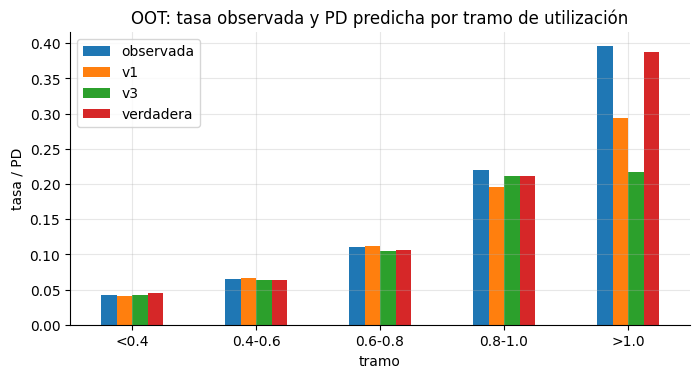

In [27]:
cal_util[["observada", "v1", "v3", "verdadera"]].plot(kind="bar", figsize=(8, 3.8), rot=0)
plt.title("OOT: tasa observada y PD predicha por tramo de utilización"); plt.ylabel("tasa / PD"); plt.show()

**Hipótesis confirmada.** El 5,4 % de OOT supera el percentil 99 de entrenamiento (1,0 % por construcción). En el tramo > 1,0 (389 casos) la tasa observada es 39,6 % y la probabilidad verdadera 38,7 %; v1 predice 29,3 % (su pendiente lineal extrapola en parte) y v3 solo 21,7 %: el último tramo del binner (utilización > 0,808, tasa 21,4 % en entrenamiento) es **plano**, así que no puede crecer más allá de lo visto. En el tramo 0,8–1,0 v3 casi acierta (21,2 % vs 22,0 % observado), mientras v1 subestima ahí (19,5 %).

In [28]:
# cuanto del desvio total de nivel viene de cada tramo: n_tramo/N * (observada - predicha)
tamano = cal_util["n"] / cal_util["n"].sum()
aporte = pd.DataFrame({"v1": tamano * (cal_util["observada"] - cal_util["v1"]),
                       "v3": tamano * (cal_util["observada"] - cal_util["v3"])})
aporte.loc["TOTAL"] = aporte.sum()
print("Desvio de nivel en OOT (observada - predicha), descompuesto por tramo de utilizacion:")
aporte

Desvio de nivel en OOT (observada - predicha), descompuesto por tramo de utilizacion:


,v1,v3
tramo,,
<0.4,0.0002,-0.0000
0.4-0.6,-0.0005,0.0004
0.6-0.8,-0.0006,0.0017
0.8-1.0,0.0048,0.0016
>1.0,0.0060,0.0104
TOTAL,0.0098,0.0140


**Cuantificación.** Con v3, el tramo > 1,0 explica 0,0104 de los 0,0140 puntos de desvío de nivel (**74 %**) y representa solo el 5,8 % de los casos. Con v1 el desvío total es algo menor (0,0098) porque su pendiente lineal acierta más en la cola, pero queda repartido entre los tramos 0,8–1,0 y > 1,0. Una consecuencia incómoda: **el modelo con mejor ordenamiento (v3) tiene peor nivel que el simple (v1) justo en la zona extrema**.

### Un intento de corrección estructural (versión 4)

Si el problema es la cola, la corrección natural es **darle al modelo una pendiente en la cola** que el binning no tiene: se añade, junto a los WoE, un término lineal por encima del último corte,

$$\text{exceso}=\max(\text{utilización}-c_{\text{último}},\,0).$$

Es una decisión con costo: el scorecard deja de ser una tabla pura de puntos por tramo, porque ese término es continuo. Se evalúa si compensa.

In [29]:
CORTE_COLA = float(bin_v3["utilizacion"].cortes_[-1])


def X_v4(d):
    X = matriz_woe(bin_v3, d)
    X["exceso_util"] = np.clip(d["utilizacion"].to_numpy() - CORTE_COLA, 0, None)
    return X


m4 = LogisticRegression(C=C_ELEGIDO, max_iter=3000).fit(X_v4(train), train["default"])
pred_v4 = lambda d: m4.predict_proba(X_v4(d))[:, 1]
print(f"coeficiente del termino de cola: {m4.coef_[0][-1]:+.3f} (logit por unidad de utilizacion sobre {CORTE_COLA:.3f})")
met_final = tabla_metricas(pred_final, "v3 final")
met_v4 = tabla_metricas(pred_v4, "v4 con cola lineal")
pd.concat([met_final, met_v4]).sort_index(kind="stable")

coeficiente del termino de cola: +0.773 (logit por unidad de utilizacion sobre 0.808)


,modelo,AUC,Gini,KS,Brier,BSS
oot,v3 final,0.7473,0.4945,0.3744,0.0997,0.1050
oot,v4 con cola lineal,0.7501,0.5002,0.3783,0.0990,0.1110
train,v3 final,0.7417,0.4834,0.3586,0.0682,0.0775
train,v4 con cola lineal,0.7423,0.4845,0.3576,0.0681,0.0787
valid,v3 final,0.7557,0.5114,0.3912,0.0672,0.0920
valid,v4 con cola lineal,0.7560,0.5121,0.3902,0.0671,0.0932


In [30]:
cal_util["v4"] = calib_por_tramo(oot).index.map(lambda _: np.nan)
tmp = pd.DataFrame({"tramo": pd.cut(oot["utilizacion"], [-np.inf, .4, .6, .8, 1.0, np.inf],
                                    labels=["<0.4", "0.4-0.6", "0.6-0.8", "0.8-1.0", ">1.0"]),
                    "v4": pred_v4(oot)}).groupby("tramo", observed=True)["v4"].mean()
cal_util["v4"] = tmp
print(cal_util[["n", "observada", "v1", "v3", "v4", "verdadera"]].round(4).to_string())
print()
print(f"Desvio total de nivel en OOT (observada - predicha):  v3={oot['default'].mean() - pred_final(oot).mean():+.4f}   v4={oot['default'].mean() - pred_v4(oot).mean():+.4f}")

            n  observada     v1     v3     v4  verdadera
tramo                                                   
<0.4      636     0.0425 0.0404 0.0427 0.0434     0.0446
0.4-0.6  2126     0.0654 0.0671 0.0641 0.0641     0.0637
0.6-0.8  2203     0.1099 0.1117 0.1048 0.1030     0.1056
0.8-1.0  1326     0.2195 0.1953 0.2116 0.2136     0.2117
>1.0      389     0.3959 0.2932 0.2172 0.2427     0.3873

Desvio total de nivel en OOT (observada - predicha):  v3=+0.0140   v4=+0.0127


**Resultado del intento v4.** La cola lineal mejora algo el ordenamiento (Gini OOT 0,494 → 0,500) y reduce un poco el desvío de nivel, pero **no resuelve la cola**: en utilización > 1,0 pasa de 21,7 % a 24,3 % frente a 39,6 % observado. El coeficiente estimado (+0,77) es mucho menor que la pendiente real en esa zona. No es un fallo de implementación: en entrenamiento solo ~1 % de los casos supera 1,0 y esos pocos datos no contienen la información. **Ningún término de modelación aprende lo que los datos no muestran.**

### Remedio realista: reentrenar con datos recientes (y un control para no confundir causas)

Si la información que falta está en la zona nueva, la única fuente es **observar esa zona**. Se compara, sobre los meses 33–35 (que ninguno de los modelos vio):

1. **Base:** el modelo v3 actual (entrenado con el 70 % del desarrollo, meses < 30).
2. **Control de volumen:** el mismo método reentrenado con **todo** el desarrollo (meses < 30). Aísla el efecto de "tener más datos".
3. **Reentrenado reciente:** entrenado con meses < 33 (incluye los meses 30–32, que ya tienen utilizaciones altas). Aísla el efecto de "tener datos recientes".

In [31]:
def ajustar_modelo(datos):
    b = {v: WoEBinner(n_bins=10, monotono=MONOTONAS[v]).fit(datos[v], datos["default"]) for v in VARS}
    X = lambda d: pd.DataFrame({v: b[v].transform(d[v]) for v in VARS}, index=d.index)
    m = LogisticRegression(C=C_ELEGIDO, max_iter=3000).fit(X(datos), datos["default"])
    return lambda d: m.predict_proba(X(d))[:, 1]


prueba_b = df[df["mes"] >= 33]
modelos_cmp = {
    "base (70% de meses<30)": pred_final,
    "control: 100% de meses<30": ajustar_modelo(df[df["mes"] < 30]),
    "reentrenado: meses<33": ajustar_modelo(df[df["mes"] < 33]),
}
tramos_cmp = pd.cut(prueba_b["utilizacion"], [-np.inf, 1.0, np.inf], labels=["util<=1.0", "util>1.0"])
filas = []
for nombre, f in modelos_cmp.items():
    pr = f(prueba_b)
    cola = tramos_cmp == "util>1.0"
    filas.append({"modelo": nombre, "observada": prueba_b["default"].mean(), "PD_media": pr.mean(),
                  "desvio_nivel": prueba_b["default"].mean() - pr.mean(),
                  "obs_cola": prueba_b.loc[cola, "default"].mean(), "PD_cola": pr[cola.to_numpy()].mean(),
                  "AUC": roc_auc_score(prueba_b["default"], pr), "Brier": brier_score_loss(prueba_b["default"], pr)})
refit = pd.DataFrame(filas).set_index("modelo")
print(f"Meses 33-35: n={len(prueba_b)}, casos con util>1.0: {int((tramos_cmp == 'util>1.0').sum())}")
refit

Meses 33-35: n=3378, casos con util>1.0: 211


,observada,PD_media,desvio_nivel,obs_cola,PD_cola,AUC,Brier
modelo,,,,,,,
base (70% de meses<30),0.1270,0.1168,0.0102,0.3981,0.2204,0.7376,0.1005
control: 100% de meses<30,0.1270,0.1172,0.0098,0.3981,0.2259,0.7391,0.1003
reentrenado: meses<33,0.1270,0.1200,0.0070,0.3981,0.2403,0.7456,0.0995


**Lectura.** (a) **Más volumen no ayuda:** el control (100 % de los meses < 30) casi no cambia nada (desvío 0,0102 → 0,0098). (b) **Datos recientes sí ayudan, pero poco:** reentrenar con meses < 33 baja el desvío a 0,0070 y sube la PD de la cola de 22,0 % a 24,0 %, aún lejos del 39,8 % observado, porque los meses 30–32 solo añaden unos cientos de casos con utilización > 1,0. (c) El AUC mejora (0,738 → 0,746). Reentrenar es el remedio correcto, pero **lento**: la información llega con el rezago con que se observa el incumplimiento.

### Un monitor de datos fuera de rango

Como el remedio depende de **darse cuenta a tiempo**, se define una alerta simple y verificable: la fracción de casos que cae fuera del rango visto en entrenamiento (por encima de su percentil 99 o por debajo del 1).

In [32]:
def fraccion_fuera_de_rango(ref, nuevo, columnas, q=0.01):
    lo, hi = ref[columnas].quantile(q), ref[columnas].quantile(1 - q)
    fuera = ((nuevo[columnas] < lo) | (nuevo[columnas] > hi))
    return fuera.mean()


UMBRAL_ALERTA = 0.03   # esperado ~1% en cada cola por construccion; 3% es tres veces lo normal
monitor = pd.DataFrame({
    "valid": fraccion_fuera_de_rango(train, valid, ["utilizacion"]),
    **{f"mes_{m}": fraccion_fuera_de_rango(train, df[df["mes"] == m], ["utilizacion"]) for m in range(26, 36, 3)},
})
monitor.T.assign(alerta=lambda t: np.where(t["utilizacion"] > UMBRAL_ALERTA, "ALERTA", "ok"))

,utilizacion,alerta
valid,0.0178,ok
mes_26,0.0296,ok
mes_29,0.0301,ALERTA
mes_32,0.0608,ALERTA
mes_35,0.0614,ALERTA


**Lectura del monitor.** La fracción fuera de rango pasa de 1,8 % en validación a más de 6 % en los meses 32 y 35. Con umbral de 3 % la alerta se activa ya en el mes 29, antes de que el desvío de nivel sea visible; el umbral es borderline (mes 26: 2,96 %) y en un caso real habría que calibrarlo con historia. Es la señal temprana que habilita el reentrenamiento y una política de contención (por ejemplo, derivar a revisión manual los casos con utilización > 1,0 mientras el modelo no tenga datos allí).

### Recalibración del intercepto con datos recientes

Si la tasa base cambió, se ajusta **solo el intercepto** para que la PD media coincida con la observada reciente. No se usa la muestra OOT para evaluar después de calibrarla con ella, por eso se divide en dos mitades: la primera para calibrar, la segunda para evaluar.

In [33]:
from scipy.optimize import brentq

oot_a = oot[oot["mes"] < 33]
oot_b = oot[oot["mes"] >= 33]
logit = lambda p: np.log(p / (1 - p))
z_a = logit(np.clip(pred_final(oot_a), 1e-6, 1 - 1e-6))
delta = brentq(lambda d: (1 / (1 + np.exp(-(z_a + d)))).mean() - oot_a["default"].mean(), -3, 3)
print(f"desplazamiento del intercepto: {delta:+.4f}")

def pred_recal(d):
    z = logit(np.clip(pred_final(d), 1e-6, 1 - 1e-6)) + delta
    return 1 / (1 + np.exp(-z))

tabla_rc = pd.DataFrame({
    "tasa_observada_b": [oot_b["default"].mean()] * 2,
    "PD_media": [pred_final(oot_b).mean(), pred_recal(oot_b).mean()],
    "Brier": [brier_score_loss(oot_b["default"], pred_final(oot_b)), brier_score_loss(oot_b["default"], pred_recal(oot_b))],
    "AUC": [roc_auc_score(oot_b["default"], pred_final(oot_b)), roc_auc_score(oot_b["default"], pred_recal(oot_b))],
}, index=["sin recalibrar", "recalibrado"])
tabla_rc

desplazamiento del intercepto: +0.1873


,tasa_observada_b,PD_media,Brier,AUC
sin recalibrar,0.1270,0.1168,0.1005,0.7376
recalibrado,0.1270,0.1356,0.1004,0.7376


### ¿Recalibrar ayuda de verdad? Un experimento rodante

Una sola ventana puede engañar. Se repite la lógica como se haría en producción: para cada mes de prueba *t*, se recalibra el intercepto con los **dos meses previos** y se mide el error en el mes *t*. Se compara contra no recalibrar. (Se asume que el resultado de cada crédito se conoce de inmediato; en la práctica hay rezago de observación, lo que empeoraría la recalibración.)

In [34]:
def delta_ventana(d):
    z = logit(np.clip(pred_final(d), 1e-6, 1 - 1e-6))
    return brentq(lambda dl: (1 / (1 + np.exp(-(z + dl)))).mean() - d["default"].mean(), -3, 3)

filas = []
for t in range(32, 36):
    ventana = df[(df["mes"] >= t - 2) & (df["mes"] < t)]
    prueba = df[df["mes"] == t]
    dl = delta_ventana(ventana)
    z = logit(np.clip(pred_final(prueba), 1e-6, 1 - 1e-6))
    p_rec = 1 / (1 + np.exp(-(z + dl)))
    obs = prueba["default"].mean()
    filas.append({"mes": t, "observada": obs, "PD_sin_recal": pred_final(prueba).mean(), "PD_recal": p_rec.mean(),
                  "error_sin": pred_final(prueba).mean() - obs, "error_recal": p_rec.mean() - obs,
                  "Brier_sin": brier_score_loss(prueba["default"], pred_final(prueba)),
                  "Brier_recal": brier_score_loss(prueba["default"], p_rec), "delta": dl})
rodante = pd.DataFrame(filas).set_index("mes")
rodante

,observada,PD_sin_recal,PD_recal,error_sin,error_recal,Brier_sin,Brier_recal,delta
mes,,,,,,,,
32,0.1515,0.1117,0.1187,-0.0398,-0.0328,0.1150,0.1142,0.0756
33,0.1184,0.1135,0.1391,-0.0048,0.0207,0.0954,0.0961,0.2550
34,0.1213,0.1154,0.1383,-0.0058,0.0170,0.0961,0.0960,0.2236
35,0.1415,0.1214,0.1269,-0.0200,-0.0145,0.1100,0.1098,0.0558


In [35]:
print(f"Error absoluto medio de nivel sin recalibrar: {rodante['error_sin'].abs().mean():.4f}")
print(f"Error absoluto medio de nivel recalibrando:   {rodante['error_recal'].abs().mean():.4f}")
print(f"Brier medio sin recalibrar: {rodante['Brier_sin'].mean():.5f} | recalibrando: {rodante['Brier_recal'].mean():.5f}")

Error absoluto medio de nivel sin recalibrar: 0.0176
Error absoluto medio de nivel recalibrando:   0.0213
Brier medio sin recalibrar: 0.10413 | recalibrando: 0.10402


Propiedad verificada: la recalibración mueve el **nivel** sin tocar el **orden** (el AUC es idéntico, 0,7376, porque desplazar el intercepto es una transformación monótona).

Resultado empírico con una sola ventana: el error de nivel en la segunda mitad (predicha − observada) cambia de signo (−0,0102 → +0,0086) y casi no se reduce; el Brier apenas se mueve (0,1005 → 0,1004). El experimento rodante lo confirma con más evidencia: **recalibrar empeoró el error medio de nivel (0,0176 → 0,0213)**. Con ventanas cortas el intercepto persigue el ruido mensual (el mes 32 tuvo 15 % de incumplimiento, unos 4 puntos sobre lo predicho) y sobrecorrige los meses siguientes.

Conclusión: la recalibración es una herramienta legítima, pero aquí trata un **síntoma**. La causa es estructural (una cola fuera de rango) y los remedios que atacan la causa son los de las secciones anteriores.

## 9. Del modelo al scorecard

Se escala la probabilidad a puntos: **600 puntos con odds buenos/malos de 30:1, y 40 puntos por cada duplicación de odds (PDO)**. Con $\text{factor}=\text{PDO}/\ln 2$ y $\text{offset}=600-\text{factor}\cdot\ln(30)$:

$$\text{score}=\text{offset}-\text{factor}\cdot\Big(\beta_0+\sum_j \beta_j\,\mathrm{WoE}_j\Big)$$

In [36]:
PDO, BASE, ODDS0 = 40, 600, 30
FACTOR = PDO / np.log(2)
OFFSET = BASE - FACTOR * np.log(ODDS0)
n_var = len(VARS)
beta0 = float(modelo.intercept_[0])
betas = dict(zip(VARS, modelo.coef_[0]))


def puntos_tabla():
    filas = []
    for v in VARS:
        t = bin_v3[v].tabla()
        for etiqueta, fila in t.iterrows():
            pts = -(betas[v] * fila["WoE"] + beta0 / n_var) * FACTOR + OFFSET / n_var
            filas.append({"variable": v, "tramo": etiqueta, "desde": fila["desde"], "hasta": fila["hasta"],
                          "n": int(fila["n"]), "tasa_default": fila["tasa_default"], "puntos": pts})
    return pd.DataFrame(filas)


tabla_puntos = puntos_tabla()
tabla_puntos.groupby("variable").head(3).round(3)

,variable,tramo,desde,hasta,n,tasa_default,puntos
0,ingreso,0,-inf,"1,569.3280",2248,0.1050,92.0440
1,ingreso,1,"1,569.3280","2,292.9560",4496,0.0890,102.6360
2,ingreso,2,"2,292.9560","2,622.4220",2248,0.0850,105.7170
9,edad,0,-inf,25.0000,1882,0.1000,96.0710
10,edad,1,25.0000,30.0000,2359,0.0990,96.8080
11,edad,2,30.0000,35.0000,2410,0.0750,112.6400
19,utilizacion,0,-inf,0.2450,2333,0.0330,163.1150
20,utilizacion,1,0.2450,0.3210,2332,0.0360,159.3270
21,utilizacion,2,0.3210,0.3860,2332,0.0440,146.1730
29,mora_previa,0,-inf,0.5000,15662,0.0630,124.5660


In [37]:
def score(d):
    z = beta0 + sum(betas[v] * bin_v3[v].transform(d[v]) for v in VARS)
    return OFFSET - FACTOR * z


s_valid = score(valid)
# consistencia: el score reproduce la PD del modelo
pd_desde_score = 1 / (1 + np.exp(-(OFFSET - s_valid) / FACTOR))
print("max |PD(modelo) - PD(score)|:", float(np.max(np.abs(pd_desde_score - pred_final(valid)))))

# consistencia: los puntos por tramo suman el score
suma_puntos = np.zeros(len(valid))
for v in VARS:
    t = tabla_puntos[tabla_puntos["variable"] == v].reset_index(drop=True)
    w = bin_v3[v].transform(valid[v])
    pts_por_woe = {round(woe, 10): p for woe, p in zip(
        [bin_v3[v].woe_na_ if i == "faltante" else bin_v3[v].woe_[i] for i in bin_v3[v].tabla().index], t["puntos"])}
    suma_puntos += np.array([pts_por_woe[round(x, 10)] for x in w])
print("max |score - suma de puntos|:", float(np.max(np.abs(suma_puntos - s_valid))))

max |PD(modelo) - PD(score)|: 2.220446049250313e-16


max |score - suma de puntos|: 2.2737367544323206e-13


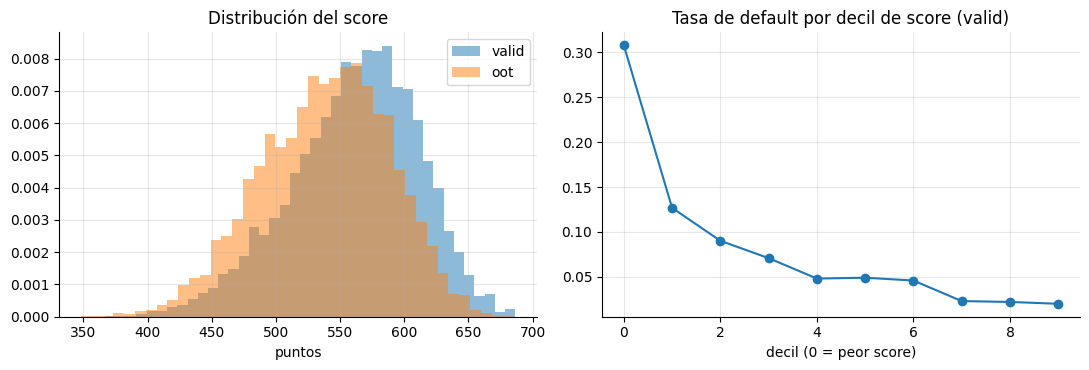

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for nombre, d in (("valid", valid), ("oot", oot)):
    ax[0].hist(score(d), bins=40, alpha=0.5, density=True, label=nombre)
ax[0].set_title("Distribución del score"); ax[0].set_xlabel("puntos"); ax[0].legend()
g = pd.qcut(score(valid), 10, duplicates="drop")
t = valid.groupby(g, observed=True)["default"].mean()
ax[1].plot(range(len(t)), t.values, "o-"); ax[1].set_title("Tasa de default por decil de score (valid)")
ax[1].set_xlabel("decil (0 = peor score)"); plt.tight_layout(); plt.show()

## 10. Estabilidad: PSI del score y de las variables

$$\mathrm{PSI}=\sum_i (a_i-e_i)\ln\frac{a_i}{e_i}$$

Umbrales usuales: <0,10 estable; 0,10–0,25 revisar; >0,25 cambio significativo.

In [39]:
def psi(esperado, actual, bins=10):
    e_ = np.asarray(esperado, float); a_ = np.asarray(actual, float)
    e_, a_ = e_[~np.isnan(e_)], a_[~np.isnan(a_)]
    cortes = np.unique(np.quantile(e_, np.linspace(0, 1, bins + 1)))
    cortes[0], cortes[-1] = -np.inf, np.inf
    pe = np.clip(np.histogram(e_, cortes)[0] / len(e_), 1e-4, None)
    pa = np.clip(np.histogram(a_, cortes)[0] / len(a_), 1e-4, None)
    return float(((pa - pe) * np.log(pa / pe)).sum())


psi_tab = pd.Series({v: psi(train[v], oot[v]) for v in VARS}, name="PSI")
psi_tab["SCORE"] = psi(score(train), score(oot))
psi_tab.to_frame().assign(alerta=lambda t: np.where(t["PSI"] > 0.25, "ROJO", np.where(t["PSI"] > 0.10, "AMBAR", "VERDE")))

,PSI,alerta
ingreso,0.0021,VERDE
edad,0.0023,VERDE
utilizacion,1.0086,ROJO
mora_previa,0.0000,VERDE
antiguedad,0.0028,VERDE
SCORE,0.2356,AMBAR


El PSI confirma lo que ya se sabía por construcción: la deriva está en `utilizacion`. Sin conocer el proceso generador, este es el tipo de tabla que lleva a investigar por qué cambió la población (cambio de política, de canal, de producto). El PSI del score (0,236) queda en ámbar, a las puertas del rojo, mientras el Gini del modelo casi no se movió: **un score puede ordenar bien y a la vez estar mal calibrado en una zona nueva**, por eso se miran las dos cosas.

## 11. Punto de corte con una función de utilidad

Supuestos (ilustrativos): ganancia de **300** por cada crédito bueno aprobado y pérdida de **2.500** por cada malo aprobado. Se busca el corte que maximiza la utilidad esperada.

In [40]:
GANANCIA, PERDIDA = 300.0, 2500.0
s = np.asarray(score(valid)); y = valid["default"].to_numpy()
cortes = np.linspace(np.quantile(s, 0.01), np.quantile(s, 0.99), 120)
filas = []
for c in cortes:
    aprobados = s >= c
    buenos = (aprobados & (y == 0)).sum(); malos = (aprobados & (y == 1)).sum()
    filas.append({"corte": c, "aprobacion": aprobados.mean(), "tasa_default_aprobados": malos / max(aprobados.sum(), 1),
                  "utilidad_por_solicitud": (GANANCIA * buenos - PERDIDA * malos) / len(y)})
curva = pd.DataFrame(filas)
mejor = curva.loc[curva["utilidad_por_solicitud"].idxmax()]
mejor.to_frame("valor")

,valor
corte,520.3308
aprobacion,0.8011
tasa_default_aprobados,0.0461
utilidad_por_solicitud,136.9748


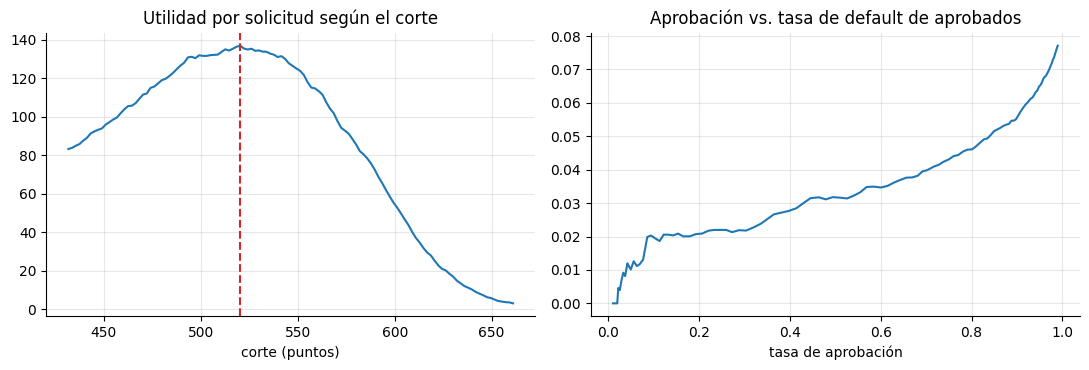

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(curva["corte"], curva["utilidad_por_solicitud"]); ax[0].axvline(mejor["corte"], color="C3", ls="--")
ax[0].set_title("Utilidad por solicitud según el corte"); ax[0].set_xlabel("corte (puntos)")
ax[1].plot(curva["aprobacion"], curva["tasa_default_aprobados"]); ax[1].set_title("Aprobación vs. tasa de default de aprobados")
ax[1].set_xlabel("tasa de aprobación"); plt.tight_layout(); plt.show()

### El corte elegido en validación, aplicado a la muestra reciente

In [42]:
c_opt = float(mejor["corte"])
s_oot = np.asarray(score(oot)); y_oot = oot["default"].to_numpy()
def utilidad(corte, s_, y_):
    a = s_ >= corte
    return (GANANCIA * (a & (y_ == 0)).sum() - PERDIDA * (a & (y_ == 1)).sum()) / len(y_), a.mean(), (y_[a].mean() if a.any() else np.nan)

cand = np.linspace(np.quantile(s_oot, 0.01), np.quantile(s_oot, 0.99), 200)
c_oot = cand[int(np.argmax([utilidad(c, s_oot, y_oot)[0] for c in cand]))]
comp = pd.DataFrame({"corte": [c_opt, c_oot]}, index=["optimo en valid", "optimo en OOT"])
comp[["utilidad", "aprobacion", "default_aprobados"]] = [utilidad(c, s_oot, y_oot) for c in comp["corte"]]
comp

,corte,utilidad,aprobacion,default_aprobados
optimo en valid,520.3308,75.2395,0.6518,0.0659
optimo en OOT,530.5016,77.0509,0.5810,0.0598


**Resultado.** Aplicado a la muestra reciente, el corte elegido en validación (520,3) rinde 75,2 de utilidad por solicitud frente a 77,1 del óptimo en OOT (530,5): el corte es **robusto** a la deriva (pierde ≈ 2,4 % del óptimo). Lo que cae es la utilidad absoluta (de 137 a 75), porque suben los malos: aprobación de 65 % con 6,6 % de incumplimiento entre aprobados, contra 80 % y 4,6 % en validación.

El corte óptimo depende de los supuestos económicos, no del modelo. Cambiar la relación pérdida/ganancia mueve el corte; por eso se muestra la curva completa y no un solo número.

In [43]:
sens = []
for perd in (1500, 2500, 4000):
    for gan in (200, 300, 500):
        u = []
        for c in cortes:
            a = s >= c
            u.append((gan * (a & (y == 0)).sum() - perd * (a & (y == 1)).sum()) / len(y))
        sens.append({"perdida": perd, "ganancia": gan, "corte_optimo": cortes[int(np.argmax(u))], "aprobacion": (s >= cortes[int(np.argmax(u))]).mean()})
pd.DataFrame(sens).pivot(index="perdida", columns="ganancia", values="corte_optimo").round(1)

ganancia,200,300,500
perdida,,,
1500,520.3000,493.3000,474.1000
2500,541.5000,520.3000,493.3000
4000,562.7000,541.5000,520.3000


## 12. Robustez

### 12.1 Intervalo de confianza del AUC en OOT (bootstrap)

In [44]:
rng = np.random.default_rng(1)
y_o = oot["default"].to_numpy(); p_o = pred_final(oot)
aucs = []
for _ in range(400):
    idx = rng.integers(0, len(y_o), len(y_o))
    aucs.append(roc_auc_score(y_o[idx], p_o[idx]))
lo, hi = np.percentile(aucs, [2.5, 97.5])
print(f"AUC OOT = {roc_auc_score(y_o, p_o):.4f}  IC95% bootstrap = [{lo:.4f}, {hi:.4f}]")

AUC OOT = 0.7473  IC95% bootstrap = [0.7295, 0.7643]


### 12.2 Sensibilidad al número de tramos

In [45]:
filas = []
for nb in (4, 6, 8, 10, 15, 20):
    bins_ = ajustar_binners_v3(train, n_bins=nb)
    m = LogisticRegression(C=C_ELEGIDO, max_iter=3000).fit(matriz_woe(bins_, train), train["default"])
    pv = m.predict_proba(matriz_woe(bins_, valid))[:, 1]; po = m.predict_proba(matriz_woe(bins_, oot))[:, 1]
    filas.append({"n_bins": nb, "tramos_totales": sum(len(b.woe_) for b in bins_.values()),
                  "AUC_valid": roc_auc_score(valid["default"], pv), "AUC_oot": roc_auc_score(oot["default"], po),
                  "IV_total": sum(b.iv_ for b in bins_.values())})
pd.DataFrame(filas)

,n_bins,tramos_totales,AUC_valid,AUC_oot,IV_total
0,4,18,0.7414,0.7298,0.6758
1,6,27,0.7519,0.7439,0.7600
2,8,34,0.7519,0.7477,0.7904
3,10,40,0.7557,0.7473,0.7955
4,15,49,0.7528,0.7512,0.8257
5,20,62,0.7531,0.7529,0.8346


El IV total sube siempre con más tramos (0,68 → 0,83): es una propiedad mecánica, **no sirve para elegir el número de tramos**. El AUC de validación se aplana desde 8–10 tramos, mientras el de OOT sigue subiendo (0,730 → 0,753) con tramos más finos; es consistente con que tramos finos ayudan en la cola, pero esa causa no se ha aislado.

### 12.3 Estabilidad frente a la semilla de partición

In [46]:
filas = []
for sd in range(8):
    tr, va = train_test_split(desarrollo, test_size=0.3, random_state=sd, stratify=desarrollo["default"])
    b = {v: WoEBinner(n_bins=10, monotono=MONOTONAS[v]).fit(tr[v], tr["default"]) for v in VARS}
    X = lambda d: pd.DataFrame({v: b[v].transform(d[v]) for v in VARS}, index=d.index)
    m = LogisticRegression(C=C_ELEGIDO, max_iter=3000).fit(X(tr), tr["default"])
    filas.append({"semilla": sd, "AUC_valid": roc_auc_score(va["default"], m.predict_proba(X(va))[:, 1]),
                  "AUC_oot": roc_auc_score(oot["default"], m.predict_proba(X(oot))[:, 1])})
est = pd.DataFrame(filas)
print(est.describe().loc[["mean", "std", "min", "max"]].round(4))

      semilla  AUC_valid  AUC_oot
mean   3.5000     0.7414   0.7484
std    2.4495     0.0081   0.0014
min    0.0000     0.7293   0.7463
max    7.0000     0.7515   0.7500


### 12.4 ¿Recupera el modelo la verdad conocida?

In [47]:
p_oot_verdadera = p_verdadera[oot.index]
corr = np.corrcoef(logit(np.clip(pred_final(oot), 1e-6, 1 - 1e-6)), logit(p_oot_verdadera))[0, 1]
auc_techo = roc_auc_score(oot["default"], p_oot_verdadera)
print(f"AUC OOT del modelo:                 {roc_auc_score(oot['default'], pred_final(oot)):.4f}")
print(f"AUC OOT usando la probabilidad real: {auc_techo:.4f}   <- techo teorico")
print(f"Correlacion de logits modelo vs verdad: {corr:.4f}")

AUC OOT del modelo:                 0.7473
AUC OOT usando la probabilidad real: 0.7493   <- techo teorico
Correlacion de logits modelo vs verdad: 0.9131


El AUC de la probabilidad verdadera (0,749) es el techo con estas variables y este ruido; el modelo queda a 0,002. **Pero el AUC no ve lo que falló en esta historia**: mide orden, no nivel. Un modelo puede casi tocar el techo en AUC y subestimar en ~17 puntos la PD de los casos más riesgosos. Por eso la calibración por tramos de la sección 8 es una prueba independiente y necesaria.

## 13. Pruebas automáticas

Estas celdas **fallan el notebook** si algo se rompe. Se ejecutan en cada corrida y desde `tests/test_notebooks.py` en la raíz del repositorio.

In [48]:
# --- 13.1 propiedades del binner ---------------------------------------------
for v in VARS:
    b = bin_v3[v]
    assert abs(b.n_.sum() + b.n_na_ - len(train)) < 1e-6, f"{v}: los tramos no suman el total"
    assert b.iv_ >= 0, f"{v}: IV negativo"
    assert np.all(np.isfinite(b.woe_)), f"{v}: WoE no finito"
    assert np.all(np.diff(b.cortes_) > 0), f"{v}: cortes no crecientes"
for v, exige in MONOTONAS.items():
    if exige:
        assert es_monotono(bin_v3[v]), f"{v}: monotonia violada"
print("OK  binner: conservacion de conteos, IV>=0, WoE finito, cortes crecientes, monotonia")

# --- 13.2 sin fuga de informacion ---------------------------------------------
assert set(train.index).isdisjoint(valid.index) and set(train.index).isdisjoint(oot.index)
assert set(valid.index).isdisjoint(oot.index)
assert train["mes"].max() < OOT_DESDE and oot["mes"].min() >= OOT_DESDE
print("OK  particiones disjuntas y OOT posterior al desarrollo")

# --- 13.3 transformacion de datos no vistos -----------------------------------
extremos = pd.DataFrame({"ingreso": [np.nan, -1e9, 1e12], "edad": [0, 200, 45], "utilizacion": [-5, 9, 0.5],
                         "mora_previa": [0, 99, 2], "antiguedad": [0, 1e6, 5]})
for v in VARS:
    w = bin_v3[v].transform(extremos[v])
    assert np.all(np.isfinite(w)), f"{v}: valores extremos producen WoE no finito"
print("OK  valores extremos y faltantes se transforman sin error")

# --- 13.4 signos del modelo ------------------------------------------------------
assert (modelo.coef_[0] < 0).all(), "coeficientes WoE deberian ser negativos"
assert np.all((modelo.coef_[0] > -1.6) & (modelo.coef_[0] < -0.5)), "con WoE bien calibrado los coeficientes deberian rondar -1"
print("OK  todos los coeficientes WoE son negativos")

# --- 13.5 probabilidades y score ----------------------------------------------
for nombre, d in (("valid", valid), ("oot", oot)):
    p = pred_final(d)
    assert ((p > 0) & (p < 1)).all()
assert np.max(np.abs(pd_desde_score - pred_final(valid))) < 1e-9, "score no reproduce la PD"
assert np.max(np.abs(suma_puntos - s_valid)) < 1e-6, "puntos por tramo no suman el score"
print("OK  PD en (0,1); el score reproduce la PD; los puntos por tramo suman el score")

# --- 13.6 desempeno minimo y estabilidad --------------------------------------
auc_valid = roc_auc_score(valid["default"], pred_final(valid))
auc_oot = roc_auc_score(oot["default"], pred_final(oot))
assert auc_valid > 0.65, f"AUC valid demasiado bajo: {auc_valid:.3f}"
assert auc_valid - auc_oot < 0.05, f"caida de AUC OOT excesiva: {auc_valid - auc_oot:.3f}"
assert auc_oot > auc_techo - 0.05, "el modelo esta lejos del techo teorico"
print(f"OK  AUC valid={auc_valid:.3f}, AUC oot={auc_oot:.3f}, techo={auc_techo:.3f}")

# --- 13.7 recalibracion: propiedades (no se asume que mejore) ----------------
assert abs(pred_recal(oot_a).mean() - oot_a["default"].mean()) < 1e-6, "la recalibracion debe igualar la media en la muestra de calibracion"
assert abs(roc_auc_score(oot_b["default"], pred_recal(oot_b)) - roc_auc_score(oot_b["default"], pred_final(oot_b))) < 1e-9
print("OK  la recalibracion iguala la media en su muestra de calibracion y no altera el AUC")

# --- 13.7b hallazgos de la seccion 8 (pruebas de caracterizacion) --------------
cola_oot = (oot["utilizacion"] > 1.0).to_numpy()
assert (oot["utilizacion"] > q99).mean() > UMBRAL_ALERTA, "la fraccion fuera de rango en OOT debe superar el umbral"
assert fraccion_fuera_de_rango(train, valid, ["utilizacion"])["utilizacion"] < UMBRAL_ALERTA, "validacion no debe disparar la alerta"
assert pred_final(oot)[cola_oot].mean() < oot.loc[cola_oot, "default"].mean() - 0.10, "v3 deberia subestimar fuertemente la cola"
assert abs(pred_final(oot)[~cola_oot].mean() - oot.loc[~cola_oot, "default"].mean()) < 0.02, "fuera de la cola el nivel debe ser razonable"
assert aporte.loc[">1.0", "v3"] / aporte.loc["TOTAL", "v3"] > 0.6, "la cola deberia explicar la mayor parte del desvio"
assert refit.loc["reentrenado: meses<33", "desvio_nivel"] < refit.loc["base (70% de meses<30)", "desvio_nivel"]
assert abs(refit.loc["control: 100% de meses<30", "desvio_nivel"] - refit.loc["base (70% de meses<30)", "desvio_nivel"]) < 0.002, "el volumen solo no deberia ayudar"
print("OK  hallazgos de la seccion 8: cola fuera de rango, subestimacion concentrada en ella, reentrenar ayuda y el volumen no")

# --- 13.8 el bootstrap contiene la estimacion puntual --------------------------
assert lo <= auc_oot <= hi
print("OK  el IC bootstrap contiene el AUC puntual")
print("\nTodas las pruebas pasaron.")

OK  binner: conservacion de conteos, IV>=0, WoE finito, cortes crecientes, monotonia
OK  particiones disjuntas y OOT posterior al desarrollo
OK  valores extremos y faltantes se transforman sin error
OK  todos los coeficientes WoE son negativos
OK  PD en (0,1); el score reproduce la PD; los puntos por tramo suman el score
OK  AUC valid=0.756, AUC oot=0.747, techo=0.749
OK  la recalibracion iguala la media en su muestra de calibracion y no altera el AUC
OK  hallazgos de la seccion 8: cola fuera de rango, subestimacion concentrada en ella, reentrenar ayuda y el volumen no
OK  el IC bootstrap contiene el AUC puntual

Todas las pruebas pasaron.


## 14. Conclusiones y límites

**Qué se aprendió en el camino**

| Paso | Qué pasó | Decisión |
|---|---|---|
| v1 cruda | Gini aceptable; PD media 1 punto por debajo en OOT (11,8 % vs 12,8 %) | No fiarse de una validación aleatoria |
| Diagnóstico | Utilización convexa, edad en U, faltantes informativos | WoE, con el faltante como tramo propio |
| v2 y v3 | Gini +4,6 puntos en validación pero solo +1,0 en OOT; v3 ≈ v2 | Monotonía donde el negocio la exige (convexa no es no monótona) |
| Hipótesis de la cola | El 74 % del desvío de nivel de v3 sale del 5,8 % de casos con utilización > 1,0 | Medir la hipótesis, no suponerla |
| Recalibración | Empeoró el error medio de nivel (0,0176 → 0,0213) | No usarla como parche con ventanas cortas |
| Cola lineal (v4) | Mejora el Gini (+0,6 puntos) pero no la cola | Los datos no contienen esa información |
| Reentrenar | Desvío 0,0102 → 0,0070; el volumen solo no ayuda | Remedio correcto, pero lento |
| Monitor | Alerta en el mes 29, antes de que el desvío fuera visible | Instalarlo como control permanente |

**Límites que no deben ocultarse**

- Los datos son **sintéticos**: el techo teórico se conoce porque se simuló. Con datos reales no existe esa referencia.
- No hay **inferencia de rechazados**: en una cartera real solo se observa el desempeño de quienes fueron aprobados, lo que sesga el modelo.
- Los supuestos de utilidad (300/2.500) son ilustrativos.
- La deriva está **diseñada** para llevar la población fuera del rango visto y así estudiar la extrapolación; es suave y monótona, mientras en la realidad hay cambios bruscos (política, canal, macro).
- Varias afirmaciones de las primeras versiones de este análisis (p. ej., que recalibrar mejoraba el nivel o que la utilización no debía ser monótona) **no sobrevivieron a los datos** y se corrigieron; las pruebas de la sección 13 fijan lo que sí se verificó.
- Un modelo real exigiría además análisis de equidad, documentación de modelo y validación independiente.

**Siguientes pasos naturales:** reemplazar los datos sintéticos por una muestra real abierta, agregar variables macro, comparar con un modelo de boosting monotónico, y medir la estabilidad con un backtest rodante por cosechas.